# 05 - Comparação entre Modelos (SVM, KNN e MLP)

### 1. Carregamento dos resultados salvos em CSV

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

res_dir = Path("../../resultados")
df_svm = pd.read_csv(res_dir / "svm_resultados.csv")
df_knn = pd.read_csv(res_dir / "knn_resultados.csv")
df_mlp = pd.read_csv(res_dir / "mlp_resultados.csv")

df_todos = pd.concat([df_svm, df_knn, df_mlp], ignore_index=True)
df_todos = df_todos.sort_values("F1_macro", ascending=False).reset_index(drop=True)
df_todos.to_csv(res_dir / "comparacao_completa.csv", index=False)

tabela_completa = df_todos[["Modelo", "Config", "Acurácia", "Precisão_macro", "Revocação_macro", "F1_macro"]].copy()
tabela_completa.columns = ["Modelo", "Configuração", "Acurácia", "Precisão (macro)", "Revocação (macro)", "F1-score (macro)"]
tabela_completa

,Modelo,Configuração,Acurácia,Precisão (macro),Revocação (macro),F1-score (macro)
0,MLP,"(128, 64) tanh",0.7762 ± 0.0126,0.729317,0.688508,0.697746
1,MLP,"(64,) relu",0.7731 ± 0.0099,0.723252,0.687648,0.696740
2,MLP,"(128, 64) relu alpha=0.01",0.7679 ± 0.0104,0.713984,0.688509,0.696359
3,SVM,linear C=1,0.7710 ± 0.0101,0.717164,0.685592,0.694568
4,SVM,rbf C=10,0.7642 ± 0.0146,0.707104,0.688505,0.694567
5,MLP,"(128, 64) relu",0.7685 ± 0.0056,0.713864,0.686077,0.693943
6,MLP,"(128, 64, 32) relu",0.7676 ± 0.0103,0.713188,0.686006,0.690542
7,SVM,rbf C=1,0.7703 ± 0.0055,0.723949,0.675665,0.687198
8,SVM,poly C=1,0.7509 ± 0.0126,0.709648,0.645241,0.656962
9,KNN,manhattan k=7,0.7113 ± 0.0118,0.661648,0.610857,0.621390


### 2. Tabela comparativa dos melhores modelos (por algoritmo)

In [2]:
df_melhores = (
    df_todos.sort_values("F1_macro", ascending=False)
    .groupby("Modelo", as_index=False)
    .first()
    .sort_values("F1_macro", ascending=False)
    .reset_index(drop=True)
)
df_melhores.to_csv(res_dir / "comparacao_melhores.csv", index=False)

tabela_melhores = df_melhores[["Modelo", "Config", "Acurácia", "Precisão_macro", "Revocação_macro", "F1_macro"]].copy()
tabela_melhores.columns = ["Modelo", "Melhor Configuração", "Acurácia", "Precisão (macro)", "Revocação (macro)", "F1-score (macro)"]
tabela_melhores

,Modelo,Melhor Configuração,Acurácia,Precisão (macro),Revocação (macro),F1-score (macro)
0,MLP,"(128, 64) tanh",0.7762 ± 0.0126,0.729317,0.688508,0.697746
1,SVM,linear C=1,0.7710 ± 0.0101,0.717164,0.685592,0.694568
2,KNN,manhattan k=7,0.7113 ± 0.0118,0.661648,0.610857,0.621390


### 3. Gráfico comparativo dos melhores modelos

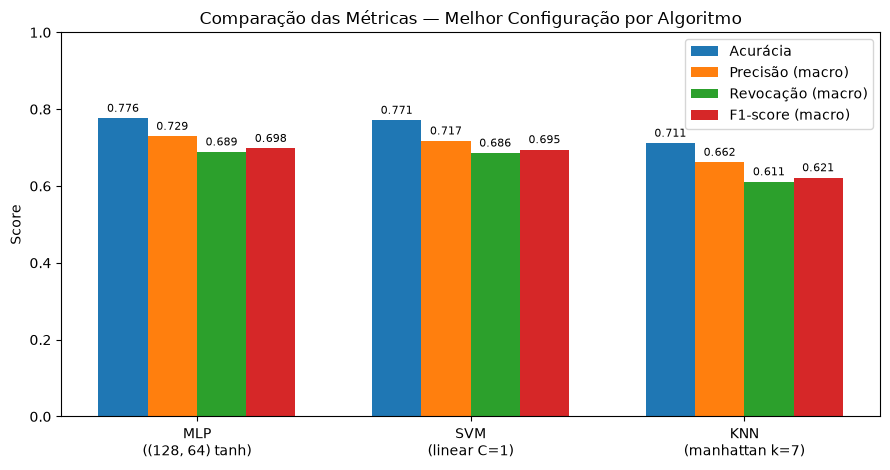

In [3]:
metricas = ["Acurácia_media", "Precisão_macro", "Revocação_macro", "F1_macro"]
rotulos = ["Acurácia", "Precisão (macro)", "Revocação (macro)", "F1-score (macro)"]

x = np.arange(len(df_melhores))
largura = 0.18

fig, ax = plt.subplots(figsize=(9, 4.8))
for i, (col, rotulo) in enumerate(zip(metricas, rotulos)):
    desloc = (i - 1.5) * largura
    bars = ax.bar(x + desloc, df_melhores[col], largura, label=rotulo)
    for b in bars:
        h = b.get_height()
        ax.text(b.get_x() + b.get_width() / 2, h + 0.01, f"{h:.3f}", ha="center", va="bottom", fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels([f"{r['Modelo']}\n({r['Config']})" for _, r in df_melhores.iterrows()])
ax.set_ylim(0, 1.0)
ax.set_ylabel("Score")
ax.set_title("Comparação das Métricas — Melhor Configuração por Algoritmo")
ax.legend(loc="upper right")
plt.tight_layout()
Path("../../media").mkdir(parents=True, exist_ok=True)
plt.savefig("../../media/comparacao_modelos_melhores.png", dpi=300, bbox_inches="tight")
plt.show()

### 4. Ranking geral de F1-score (macro) entre todas as configurações

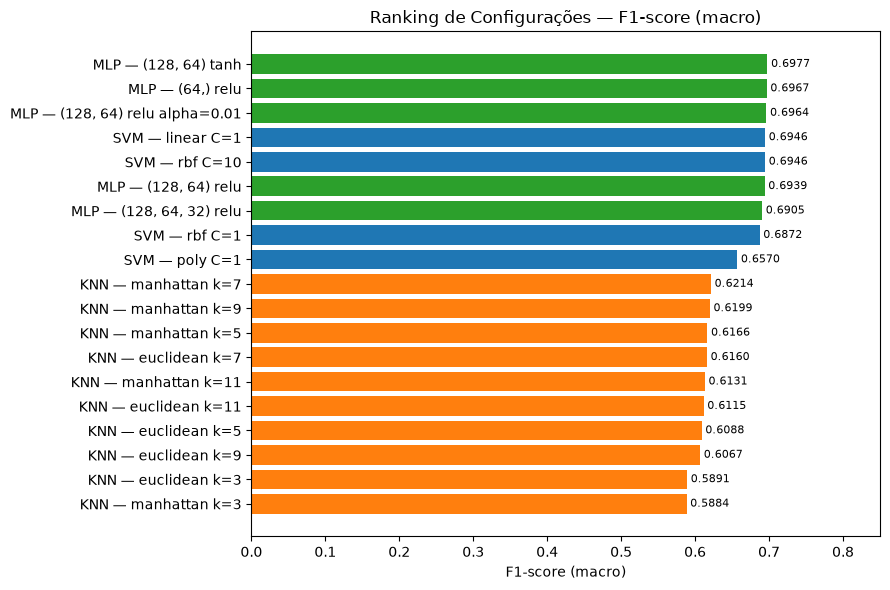

In [4]:
df_rank = df_todos.sort_values("F1_macro", ascending=True).reset_index(drop=True)
cores = {"SVM": "#1f77b4", "KNN": "#ff7f0e", "MLP": "#2ca02c"}

fig, ax = plt.subplots(figsize=(9, 6))
labels = [f"{r['Modelo']} — {r['Config']}" for _, r in df_rank.iterrows()]
colors = [cores[m] for m in df_rank["Modelo"]]

bars = ax.barh(labels, df_rank["F1_macro"], color=colors)
for b in bars:
    w = b.get_width()
    ax.text(w + 0.005, b.get_y() + b.get_height() / 2, f"{w:.4f}", va="center", fontsize=8)

ax.set_xlim(0, 0.85)
ax.set_xlabel("F1-score (macro)")
ax.set_title("Ranking de Configurações — F1-score (macro)")
plt.tight_layout()
Path("../../media").mkdir(parents=True, exist_ok=True)
plt.savefig("../../media/comparacao_modelos_f1.png", dpi=300, bbox_inches="tight")
plt.show()